# 01 · Dataset 1 — 당일·직전일 정보 5개 피처 (KODEX 200, 069500)

**이 노트북이 하는 일**

1. FinanceDataReader(FDR)에서 KODEX 200 일봉 원천을 수집하고, 응답을 그대로 저장한다 (원천 스냅샷 + SHA-256).
2. 원천을 **클리닝**한다 — 자료형·중복·가격 관계·거래량·조정 기준을 검사만 하고, 근거 없는 수정은 하지 않는다.
3. 클리닝된 종가로 **급변 구간**(20일 변동성이 60일 변동성을 위로 넘었다가 다시 내려오기 전까지)을 만든다. 이 구간 표는 02·03 노트북이 같이 쓴다.
4. 급변 구간의 하루하루에 대해 **당일·직전일 정보만으로 만든 5개 피처**를 계산하고, 오토인코더 학습용 가변 길이 배열로 저장한다.

**하지 않는 것**: 모델 학습, 학습/검증/시험 분할, 표준화 적합 (분할은 모델 설계와 함께 정하기로 했으므로 보류 — 근거 의견만 `split_manifest.json` 에 쓴다).

**데이터 정의 요약**

| 항목 | 값 |
|---|---|
| 종목 | KODEX 200 (`069500`) |
| 수집 기간 | 2017-01-01 ~ 2026-10-23 (2017–2018 은 변동성 계산용 워밍업) |
| 분석 기간 | 2019-01-01 ~ 2026-10-23 |
| 급변 상태 | 20일 연환산 변동성 > 60일 연환산 변동성 (같으면 급변 아님) |
| 학습 표본 | 시작·종료가 모두 확인된(`complete`) 2019 이후 사건 |
| 피처 | `close`, `return_1d`, `gap_1d`, `daily_range`, `volume` |

## 2. 실험 설정값
모든 경로·기간·창 길이·시드를 이 셀 한 곳에서 정한다. 다른 셀은 이 값만 참조한다.

In [1]:
from pathlib import Path  # 운영체제와 무관하게 경로를 다루기 위해 pathlib 사용

ROOT = Path.cwd().parent  # 노트북은 notebooks/ 에서 실행되므로 그 상위 폴더가 프로젝트 루트
TICKER = "069500"  # KODEX 200 종목코드 — 앞자리 0 을 보존하려고 문자열로 둔다
FETCH_START = "2017-01-01"  # 과거 계산용(워밍업) 수집 시작일
ANALYSIS_START = "2019-01-01"  # 연구 표본 시작일
ANALYSIS_END = "2026-10-23"  # 연구 표본 종료일 — 이후 데이터는 받아도 쓰지 않는다
SHORT_W, LONG_W = 20, 60  # 단기·장기 변동성 창 길이 (거래일 수)
ANNUAL = 252  # 연환산에 쓰는 연간 거래일 수
SEED = 20261024  # 정상 비교 구간 무작위 선택에 쓰는 고정 시드
REFETCH = False  # False 면 저장된 원천 스냅샷을 재사용해 API 를 다시 부르지 않는다 (재현성)
MAX_RETRY = 3  # API 재시도 횟수 상한
REGIME_VERSION = "xover_v1_20_60"  # 급변 구간 정의 버전 문자열 (이벤트 표에 기록)
FEATURES = ["close", "return_1d", "gap_1d", "daily_range", "volume"]  # Dataset 1 피처 이름과 순서 (배열 마지막 축 순서)

RAW = ROOT / "data/raw"  # 원천 스냅샷 폴더
CLEAN = ROOT / "data/clean"  # 클리닝 결과 폴더
EVENTS = ROOT / "data/events"  # 급변 구간 폴더
QUALITY = ROOT / "data/quality"  # 품질 보고서 폴더
PROC = ROOT / "data/processed/dataset_1"  # Dataset 1 원값 폴더
TRAIN = ROOT / "data/training/dataset_1"  # Dataset 1 학습용 배열 폴더
FIG = ROOT / "reports/figures"  # 그림 저장 폴더
for d in (RAW, CLEAN, EVENTS, QUALITY, PROC, TRAIN, FIG):  # 필요한 폴더를 모두 만든다
    d.mkdir(parents=True, exist_ok=True)  # 이미 있으면 그대로 둔다

## 3. 필수 라이브러리 및 버전 확인
버전을 출력하고 manifest 에 남긴다. 같은 버전이어야 같은 결과가 나온다.

In [2]:
import hashlib  # 파일·데이터 내용의 SHA-256 해시 계산
import json  # 보고서를 JSON 으로 저장
import platform  # 파이썬 버전 기록
import time  # 재시도 사이 대기
from datetime import datetime, timezone, timedelta  # 수집 시각 기록 (Asia/Seoul = UTC+9)

import numpy as np  # 수치 계산
import pandas as pd  # 표 형태 데이터 처리
import matplotlib  # 그림 라이브러리 버전 확인용
import matplotlib.pyplot as plt  # 그림 그리기
import FinanceDataReader as fdr  # 기본 수집원

KST = timezone(timedelta(hours=9))  # 기준 시간대 Asia/Seoul
VERSIONS = {  # 결과에 영향을 주는 라이브러리 버전 사전
    "python": platform.python_version(),  # 파이썬
    "numpy": np.__version__,  # numpy
    "pandas": pd.__version__,  # pandas
    "matplotlib": matplotlib.__version__,  # matplotlib
    "FinanceDataReader": fdr.__version__,  # 수집 라이브러리
}
try:  # pykrx 는 보조 검증용이라 없어도 노트북은 계속 진행한다
    import pykrx  # 보조 수집원
    from pykrx import stock  # ETF 일봉 함수가 있는 모듈
    VERSIONS["pykrx"] = getattr(pykrx, "__version__", "unknown")  # 버전 기록
except Exception as exc:  # 설치되지 않았거나 import 실패
    stock = None  # 보조 검증을 건너뛰었다는 표시
    VERSIONS["pykrx"] = f"IMPORT_FAILED: {exc!r}"  # 실패 사유 기록
plt.rcParams["font.family"] = ["NanumSquare", "Noto Sans CJK KR", "DejaVu Sans"]  # 한글 글꼴 (없으면 다음 후보)
plt.rcParams["axes.unicode_minus"] = False  # 한글 글꼴에서 음수 부호가 깨지지 않게
print(json.dumps(VERSIONS, indent=1, ensure_ascii=False))  # 버전 출력

{
 "python": "3.12.3",
 "numpy": "2.4.6",
 "pandas": "3.0.3",
 "matplotlib": "3.11.0",
 "FinanceDataReader": "0.9.202",
 "pykrx": "1.0.51"
}


### 공통 도우미 함수
- `save_pair`: 표를 parquet 와 **같은 이름의 csv** 로 함께 저장한다 (계약: 모든 parquet 에 대응 csv).
- `content_hash`: 파일 바이트가 아니라 **표의 내용**으로 해시를 만든다. parquet 파일은 같은 내용이어도 바이트가 달라질 수 있어서다.
- `file_sha256`: 원천 파일 자체의 무결성 확인용 해시.

In [3]:
def save_pair(df: pd.DataFrame, path: Path) -> None:
    """df 를 parquet 와 같은 이름의 csv 로 저장한다."""
    df.to_parquet(path, index=False)  # 자료형을 보존하는 parquet (학습 코드용)
    df.to_csv(path.with_suffix(".csv"), index=False)  # 사람이 열어 볼 수 있는 csv (같은 내용)


def content_hash(df: pd.DataFrame) -> str:
    """행 순서까지 포함한 표 내용의 SHA-256 (인덱스 제외)."""
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=False).values.tobytes()).hexdigest()  # 행별 해시를 이어 붙여 다시 해시


def file_sha256(path: Path) -> str:
    """파일 바이트의 SHA-256."""
    return hashlib.sha256(path.read_bytes()).hexdigest()  # 파일 전체를 읽어 해시


def save_json(obj: dict, path: Path) -> None:
    """한글이 그대로 보이는 JSON 저장."""
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")  # 날짜 등은 문자열로 변환

## 4. 입력 데이터 확인
이 노트북은 API 가 입력이다. 저장된 원천 스냅샷이 있는지와 `REFETCH` 설정을 확인한다.

In [4]:
RAW_PQ = RAW / f"{TICKER}_fdr_raw.parquet"  # 원천 스냅샷 경로
RAW_META = RAW / f"{TICKER}_fdr_raw.json"  # 수집 메타데이터 경로
use_cache = RAW_PQ.exists() and RAW_META.exists() and not REFETCH  # 캐시 사용 조건
print("원천 스냅샷 존재:", RAW_PQ.exists(), "| REFETCH:", REFETCH, "| 캐시 사용:", use_cache)  # 상태 출력

원천 스냅샷 존재: True | REFETCH: False | 캐시 사용: True


## 5. 원천 수집 (FinanceDataReader, 보조 pykrx)
- FDR `DataReader` 를 최대 3회 시도하고, 시도마다 결과(성공/실패, 행 수, 오류)를 기록한다.
- 받은 응답은 **클리닝 전에** 그대로 저장한다 (컬럼 이름만 소문자로 바꾸고 `Change` 는 `change_source` 로 보존).
- pykrx 는 같은 기간을 받아 **비교만** 한다. 두 출처를 날짜별로 섞지 않는다.

In [5]:
def fetch_with_retry(fn, label: str):
    """fn() 을 최대 MAX_RETRY 회 시도하고 (결과 또는 None, 시도 기록 리스트)를 돌려준다."""
    attempts = []  # 시도별 기록을 담는 리스트
    for k in range(1, MAX_RETRY + 1):  # 1회차부터 상한까지
        t0 = time.time()  # 소요 시간 측정 시작
        try:  # 네트워크 오류를 잡기 위해
            out = fn()  # 실제 API 호출
            n = 0 if out is None else len(out)  # 응답 행 수
            attempts.append({"source": label, "attempt": k, "ok": n > 0, "rows": n, "error": None, "sec": round(time.time() - t0, 2)})  # 기록
            if n > 0:  # 행이 있으면 성공으로 보고 종료
                return out, attempts  # 결과와 기록 반환
        except Exception as exc:  # 예외는 실패로 기록
            attempts.append({"source": label, "attempt": k, "ok": False, "rows": 0, "error": repr(exc)[:300], "sec": round(time.time() - t0, 2)})  # 오류 기록
        time.sleep(2 ** (k - 1))  # 1·2·4초 지수 대기 후 재시도
    return None, attempts  # 모든 시도 실패 (0행도 실패로 본다)


if use_cache:  # 캐시를 쓰면 API 를 부르지 않는다
    raw = pd.read_parquet(RAW_PQ)  # 저장된 원천 그대로 읽기
    meta = json.loads(RAW_META.read_text(encoding="utf-8"))  # 수집 당시 메타데이터
    assert file_sha256(RAW_PQ) == meta["sha256"], "원천 스냅샷 해시가 메타데이터와 다르다"  # 원천 불변성 확인
    print("캐시 사용 — 수집 시각:", meta["collected_at"])  # 언제 받은 자료인지 출력
else:  # 새로 수집
    resp, fdr_attempts = fetch_with_retry(lambda: fdr.DataReader(TICKER, FETCH_START, ANALYSIS_END), "FinanceDataReader")  # FDR 호출
    if resp is None:  # FDR 이 실패하면 데이터를 만들지 않고 중단
        raise RuntimeError(f"FDR 수집 실패: {fdr_attempts}")  # 실패를 성공으로 기록하지 않는다
    raw = resp.reset_index()  # 날짜 인덱스를 컬럼으로 꺼낸다
    raw = raw.rename(columns={"Date": "date", "Open": "open", "High": "high", "Low": "low", "Close": "close", "Volume": "volume", "Change": "change_source"})  # 계약 컬럼명
    raw["date"] = pd.to_datetime(raw["date"])  # 날짜형으로 통일
    raw = raw[raw["date"] <= pd.Timestamp(ANALYSIS_END)].copy()  # 종료일 이후 행은 사용하지 않는다
    raw.insert(0, "ticker", TICKER)  # 종목코드 컬럼 (문자열)
    raw["source"] = "FinanceDataReader.DataReader"  # 출처
    raw["collected_at"] = datetime.now(KST).isoformat(timespec="seconds")  # 수집 시각 (KST)
    raw["source_version"] = fdr.__version__  # 라이브러리 버전
    raw["price_adjustment_policy"] = "FDR 제공값 그대로 (종가 분배 소급조정 추정 — 클리닝 단계에서 O/H/L 조정 일관성 검사)"  # 조정 정책 기록
    raw.to_parquet(RAW_PQ, index=False)  # 클리닝 전 원천 저장 (불변 스냅샷)
    meta = {  # 수집 메타데이터
        "ticker": TICKER, "source": "FinanceDataReader", "source_version": fdr.__version__,  # 출처·버전
        "request": {"symbol": TICKER, "start": FETCH_START, "end": ANALYSIS_END},  # 수집 파라미터
        "collected_at": raw["collected_at"].iloc[0],  # 수집 시각
        "first_date": str(raw["date"].min().date()), "last_date": str(raw["date"].max().date()),  # 실제 첫·마지막 거래일
        "rows": int(len(raw)), "columns": list(raw.columns),  # 행 수와 컬럼 목록
        "attempts": fdr_attempts, "sha256": file_sha256(RAW_PQ),  # 시도 기록과 파일 해시
    }
    save_json(meta, RAW_META)  # 메타 저장
raw.to_csv(RAW / f"{TICKER}_fdr_raw.csv", index=False)  # 원천 csv 쌍 (parquet 와 같은 내용)
print(meta["first_date"], "~", meta["last_date"], "|", meta["rows"], "행 |", meta["attempts"])  # 수집 결과 출력
raw.head()  # 원천 앞부분 확인

캐시 사용 — 수집 시각: 2026-10-24T15:32:06+09:00
2017-01-02 ~ 2026-10-23 | 2403 행 | [{'source': 'FinanceDataReader', 'attempt': 1, 'ok': True, 'rows': 2403, 'error': None, 'sec': 7.53}]


,ticker,date,open,high,low,close,volume,change_source,source,collected_at,source_version,price_adjustment_policy
0,069500,2017-01-02,21586,21720,21512,21663,2066076,0.003381,FinanceDataReader.DataReader,2026-10-24T15:32:06+09:00,0.9.202,FDR 제공값 그대로 (종가 분배 소급조정 추정 — 클리닝 단계에서 O/H/L 조정...
1,069500,2017-01-03,21720,21834,21694,21834,4450261,0.007894,FinanceDataReader.DataReader,2026-10-24T15:32:06+09:00,0.9.202,FDR 제공값 그대로 (종가 분배 소급조정 추정 — 클리닝 단계에서 O/H/L 조정...
2,069500,2017-01-04,21825,21865,21813,21859,5289431,0.001145,FinanceDataReader.DataReader,2026-10-24T15:32:06+09:00,0.9.202,FDR 제공값 그대로 (종가 분배 소급조정 추정 — 클리닝 단계에서 O/H/L 조정...
3,069500,2017-01-05,21834,21855,21764,21773,7996126,-0.003934,FinanceDataReader.DataReader,2026-10-24T15:32:06+09:00,0.9.202,FDR 제공값 그대로 (종가 분배 소급조정 추정 — 클리닝 단계에서 O/H/L 조정...
4,069500,2017-01-06,21821,21909,21817,21865,3768174,0.004225,FinanceDataReader.DataReader,2026-10-24T15:32:06+09:00,0.9.202,FDR 제공값 그대로 (종가 분배 소급조정 추정 — 클리닝 단계에서 O/H/L 조정...


### 보조 수집원 pykrx 와 비교
같은 기간을 받아 겹치는 날짜의 종가 차이를 본다. 결과는 기록만 하고 데이터에는 섞지 않는다.
캐시 재실행에서는 비교 기록을 다시 만들지 않고 저장된 기록을 읽는다 (API 를 부르지 않기 위해).

In [6]:
PYKRX_LOG = RAW / f"{TICKER}_pykrx_check.json"  # 보조 검증 기록 경로
if use_cache and PYKRX_LOG.exists():  # 재실행이면 저장된 기록 사용
    pykrx_check = json.loads(PYKRX_LOG.read_text(encoding="utf-8"))  # 이전 비교 결과
else:  # 처음 실행이면 실제로 호출
    if stock is None:  # 설치되지 않은 경우
        pykrx_check = {"status": "NOT_AVAILABLE", "attempts": [], "reason": VERSIONS["pykrx"]}  # 사유 기록
    else:  # 호출 가능
        px, att = fetch_with_retry(lambda: stock.get_etf_ohlcv_by_date(FETCH_START.replace("-", ""), ANALYSIS_END.replace("-", ""), TICKER), "pykrx")  # pykrx 호출
        if px is None:  # 0행 또는 실패
            pykrx_check = {"status": "FAILED_OR_EMPTY", "attempts": att, "note": "보조 검증 불가 — FDR 단일 출처로 진행 (출처 혼합 없음)"}  # 실패 기록
        else:  # 받았으면 종가 비교
            pc = px.iloc[:, px.columns.str.contains("종가")].iloc[:, 0]  # 종가 컬럼 선택
            pc.index = pd.to_datetime(pc.index)  # 날짜형 인덱스
            fc = raw.set_index("date")["close"]  # FDR 종가
            ov = fc.index.intersection(pc.index)  # 겹치는 날짜
            rel = (fc[ov] / pc[ov] - 1).abs()  # 상대 차이
            pykrx_check = {"status": "OK", "attempts": att, "overlap_days": int(len(ov)), "max_rel_diff_close": float(rel.max()), "share_rel_diff_gt_1e-6": float((rel > 1e-6).mean())}  # 비교 요약
    save_json(pykrx_check, PYKRX_LOG)  # 기록 저장
print(json.dumps(pykrx_check, ensure_ascii=False)[:600])  # 결과 출력

{"status": "FAILED_OR_EMPTY", "attempts": [{"source": "pykrx", "attempt": 1, "ok": false, "rows": 0, "error": null, "sec": 0.05}, {"source": "pykrx", "attempt": 2, "ok": false, "rows": 0, "error": null, "sec": 0.0}, {"source": "pykrx", "attempt": 3, "ok": false, "rows": 0, "error": null, "sec": 0.0}], "note": "보조 검증 불가 — FDR 단일 출처로 진행 (출처 혼합 없음)"}


## 6. 데이터 클리닝 및 품질 검증
클리닝은 **원천의 무결성을 확인하고 정리하는 단계**다. 피처는 만들지 않는다.

| 검사 | 처리 |
|---|---|
| 자료형 | 날짜형·숫자형 변환 가능 여부 |
| 중복 거래일 | 값이 같은 중복은 제거 가능, 값이 다른 충돌 중복은 임의 선택 금지(중단) |
| 가격 | 양수인지, 고가 ≥ 시가·종가·저가, 저가 ≤ 시가·종가 |
| 거래량 | 음수 금지, 0 은 거래정지 후보로 목록화 |
| 결측 | 컬럼별 개수 |
| 조정 기준 | 연도별 시가갭 중앙값, 종가가 고저 범위 밖인 비율, KS200 지수 대비 시가·종가 비율 비교 |
| 극단 수익률 | 제거하지 않고 목록만 (급변 사건이 연구 대상) |

휴장일 행은 만들지 않는다.

In [7]:
df = raw[["ticker", "date", "open", "high", "low", "close", "volume", "change_source"]].copy()  # 클리닝 대상 컬럼만 복사 (원천은 보존)
df["ticker"] = df["ticker"].astype(str)  # 종목코드 문자열 보존
df["date"] = pd.to_datetime(df["date"])  # 날짜형
num_cols = ["open", "high", "low", "close", "volume", "change_source"]  # 숫자여야 하는 컬럼 리스트
coerced = {c: int(pd.to_numeric(df[c], errors="coerce").isna().sum() - df[c].isna().sum()) for c in num_cols}  # 숫자 변환 시 새로 생기는 결측 = 변환 불가 값 수
for c in num_cols:  # 숫자형 변환
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")  # 모두 float64 로 통일 (거래량도 결측 표현을 위해)
df = df.sort_values("date", kind="mergesort").reset_index(drop=True)  # 날짜 오름차순 (안정 정렬)

dup_mask = df.duplicated(["ticker", "date"], keep=False)  # 같은 (종목, 날짜)가 여러 번 나온 행
dup_rows = df[dup_mask]  # 중복 행들
identical_dup = int(df.duplicated(keep="first").sum())  # 모든 값이 같은 중복 수
conflict_dup = int(dup_rows.drop_duplicates().duplicated(["ticker", "date"]).sum())  # 값이 다른 충돌 중복 수
assert conflict_dup == 0, "값이 충돌하는 중복 거래일 — 임의 선택 금지"  # 계약: 충돌 중복은 중단
removed_identical = df[df.duplicated(keep="first")]  # 제거될 동일 중복 행 (보고용)
df = df.drop_duplicates(keep="first").reset_index(drop=True)  # 동일 중복만 제거

missing = df.isna().sum().astype(int).to_dict()  # 컬럼별 결측 개수
nonpos = df.loc[(df[["open", "high", "low", "close"]] <= 0).any(axis=1), "date"]  # 양수가 아닌 가격이 있는 날
neg_vol = df.loc[df["volume"] < 0, "date"]  # 음수 거래량
zero_vol = df.loc[df["volume"] == 0, "date"]  # 거래량 0 (거래정지 후보)
ohlc_bad = df.loc[(df["high"] < df[["open", "close", "low"]].max(axis=1)) | (df["low"] > df[["open", "close"]].min(axis=1)), "date"]  # 고가·저가 관계 위반
assert len(nonpos) == 0 and len(neg_vol) == 0, "비양수 가격 또는 음수 거래량"  # 계산이 불가능한 값이면 중단

lr_tmp = np.log(df["close"]).diff()  # 극단 관측 목록용 임시 로그수익률 (피처 아님)
z = (lr_tmp - lr_tmp.mean()) / lr_tmp.std(ddof=1)  # 전체 표준화 점수 (목록 작성 기준일 뿐, 데이터 수정에 쓰지 않음)
extreme = df.loc[z.abs() > 5, ["date", "close"]].assign(log_return=lr_tmp[z.abs() > 5].round(5))  # |z|>5 극단 관측 (보존)

# 조정 기준 검사: O/H/L 이 종가와 같은 기준으로 조정됐는지
year = df["date"].dt.year  # 연도
gap_raw = df["open"] / df["close"].shift(1) - 1  # 시가갭 (조정 기준이 다르면 연도별로 치우친다)
basis = pd.DataFrame({"gap_median": gap_raw.groupby(year).median(), "close_outside_hl_share": (~df["close"].between(df["low"], df["high"])).groupby(year).mean()})  # 연도별 요약
idx_status = "OK"  # KS200 비교 상태
try:  # 지수 수집은 검사용이라 실패해도 기록만
    ks = fdr.DataReader("KS200", FETCH_START, ANALYSIS_END) if not use_cache else None  # 재실행에서는 호출하지 않음
    if ks is not None and len(ks):  # 받았으면
        j = df.set_index("date")[["open", "close"]].join(ks[["Open", "Close"]], how="inner")  # 같은 날짜만
        basis["close_over_ks200"] = (j["close"] / j["Close"]).groupby(j.index.year).median()  # 종가/지수 종가
        basis["open_over_ks200"] = (j["open"] / j["Open"]).groupby(j.index.year).median()  # 시가/지수 시가
        basis.to_csv(QUALITY / "adjustment_basis_by_year.csv")  # 재실행 때 쓰려고 저장
    elif (QUALITY / "adjustment_basis_by_year.csv").exists():  # 재실행: 저장된 검사 결과 사용
        basis = pd.read_csv(QUALITY / "adjustment_basis_by_year.csv", index_col=0)  # 이전 결과 읽기
        idx_status = "CACHED"  # 상태 표시
except Exception as exc:  # 지수 수집 실패
    idx_status = f"KS200_FAILED: {exc!r}"  # 사유 기록
basis_ok = bool((basis["close_outside_hl_share"] == 0).all())  # 종가가 항상 고저 범위 안이면 같은 기준으로 판단
if "open_over_ks200" in basis:  # 지수 비교가 있으면 시가·종가 비율 차이도 확인
    basis["ratio_gap"] = (basis["open_over_ks200"] / basis["close_over_ks200"] - 1).abs()  # 같은 기준이면 거의 0
    basis_ok = basis_ok and bool((basis["ratio_gap"] < 0.01).all())  # 1% 미만이면 같은 기준
print(basis.round(5))  # 연도별 조정 기준 검사표
print("O/H/L/C 같은 조정 기준:", basis_ok, "| 지수 비교:", idx_status)  # 판정

df["is_warmup"] = df["date"] < pd.Timestamp(ANALYSIS_START)  # 2017–2018 워밍업 표시
CLEAN_PQ = CLEAN / f"{TICKER}_daily_clean.parquet"  # 클리닝 결과 경로
save_pair(df, CLEAN_PQ)  # parquet + csv 저장
cleaning_report = {  # 클리닝 보고 항목
    "raw_rows": int(len(raw)), "clean_rows": int(len(df)),  # 원천·클리닝 후 행 수
    "duplicate_rows_identical_removed": identical_dup, "conflicting_duplicates": conflict_dup,  # 중복
    "non_numeric_values_by_column": coerced, "missing_by_column": missing,  # 자료형·결측
    "price_relation_violations": int(len(ohlc_bad)), "price_relation_violation_dates": [str(d.date()) for d in ohlc_bad],  # OHLC 위반
    "nonpositive_price_rows": int(len(nonpos)), "negative_volume_rows": int(len(neg_vol)),  # 가격·거래량 이상
    "zero_volume_rows": int(len(zero_vol)), "zero_volume_dates": [str(d.date()) for d in zero_vol],  # 거래량 0
    "adjustment_basis_same": basis_ok, "adjustment_basis_by_year": basis.round(6).reset_index().to_dict("records"), "ks200_check": idx_status,  # 조정 기준
    "removed_or_modified": [{"date": str(r.date.date()), "action": "removed_identical_duplicate"} for r in removed_identical.itertuples()],  # 제거·수정 목록
    "modification_policy": "값 수정 없음. 동일 중복만 제거 가능, 휴장일 행 생성 없음, 극단값 보존",  # 정책
    "preserved_extreme_observations": extreme.assign(date=extreme["date"].dt.date.astype(str)).to_dict("records"),  # 보존한 극단 관측
    "warmup_rows": int(df["is_warmup"].sum()), "analysis_rows": int((~df["is_warmup"]).sum()),  # 워밍업·분석 행 수
    "clean_content_hash": content_hash(df), "raw_sha256": meta["sha256"],  # 해시
}
save_json(cleaning_report, QUALITY / "cleaning_report.json")  # 보고서 저장
print({k: cleaning_report[k] for k in ["raw_rows", "clean_rows", "duplicate_rows_identical_removed", "conflicting_duplicates", "price_relation_violations", "zero_volume_rows", "adjustment_basis_same"]})  # 요약 출력
extreme  # 보존한 극단 관측 표

      gap_median  close_outside_hl_share
date                                    
2017     0.00097                     0.0
2018     0.00068                     0.0
2019     0.00042                     0.0
2020     0.00214                     0.0
2021     0.00114                     0.0
2022     0.00018                     0.0
2023     0.00076                     0.0
2024     0.00067                     0.0
2025     0.00243                     0.0
2026     0.00218                     0.0
O/H/L/C 같은 조정 기준: True | 지수 비교: OK
{'raw_rows': 2403, 'clean_rows': 2403, 'duplicate_rows_identical_removed': 0, 'conflicting_duplicates': 0, 'price_relation_violations': 0, 'zero_volume_rows': 0, 'adjustment_basis_same': True}


,date,close,log_return
789,2020-03-24,19579.0,0.08876
1866,2024-08-05,32170.0,-0.09627
2245,2026-03-04,75412.0,-0.13309
2246,2026-03-05,83032.0,0.09626
2265,2026-04-01,81641.0,0.08558
2309,2026-06-08,119319.0,-0.09161
2310,2026-06-09,129868.0,0.08472
2320,2026-06-23,132553.0,-0.11061
2327,2026-07-02,123281.0,-0.08527
2334,2026-07-13,108601.0,-0.10282


## 7. 급변 구간 생성 (공통 — 02·03 노트북이 읽는다)
**정제** 단계의 첫 작업이다. 클리닝된 종가에서

- 일별 로그수익률 `lr_t = ln(close_t / close_{t-1})`
- `vol20_t` = 최근 20개 로그수익률 표준편차(ddof=1) × √252, `vol60_t` 도 같은 방식 (정확히 20·60개가 있을 때만)
- 급변 상태 `state_t = vol20_t > vol60_t` (같으면 급변 아님)

를 만든다. 상태가 False → True 로 바뀐 날이 **시작일**, True 가 끝나는 마지막 날이 **종료일**(`end_date`), 그 다음 False 날이 **하향 교차일**(`cross_down_date`)이다. 길이 제한은 없다.
이 판정에 쓴 변동성 값은 `regime_daily_audit.parquet` 에 따로 저장하고 **모델 입력에는 넣지 않는다**.

In [8]:
aud = df[["date", "close"]].copy()  # 감사표: 날짜·종가
aud["lr"] = np.log(aud["close"]).diff()  # 로그수익률 (첫날은 직전 종가가 없어 결측)
aud["vol20"] = aud["lr"].rolling(SHORT_W, min_periods=SHORT_W).std(ddof=1) * np.sqrt(ANNUAL)  # 20일 연환산 변동성
aud["vol60"] = aud["lr"].rolling(LONG_W, min_periods=LONG_W).std(ddof=1) * np.sqrt(ANNUAL)  # 60일 연환산 변동성
aud["valid"] = aud["vol20"].notna() & aud["vol60"].notna()  # 두 변동성이 모두 있는 날만 판정
aud["state"] = aud["valid"] & (aud["vol20"] > aud["vol60"])  # 급변 상태 (같으면 False)

events, cur = [], None  # 사건 리스트, 진행 중 사건 (시작 위치, 좌측 미확인 여부)
vpos = np.flatnonzero(aud["valid"].to_numpy())  # 판정 가능한 행 위치
st = aud["state"].to_numpy()  # 상태 배열
dates = aud["date"].to_numpy()  # 날짜 배열
for n, i in enumerate(vpos):  # 판정 가능한 날을 시간순으로 순회
    if st[i] and cur is None:  # 급변이 새로 시작
        cur = (i, n == 0)  # 첫 판정일부터 True 면 시작을 확인할 수 없다 (left_censored)
    elif not st[i] and cur is not None:  # 급변이 끝남 (하향 교차)
        events.append((cur[0], vpos[n - 1], i, "left_censored" if cur[1] else "complete"))  # (시작, 마지막 포함일, 하향 교차일, 상태)
        cur = None  # 진행 중 사건 초기화
if cur is not None:  # 마지막 관측일까지 급변이 이어지면
    events.append((cur[0], vpos[-1], None, "right_censored"))  # 종료 미확인

ev = pd.DataFrame([{  # 이벤트 표 (사건 표 스키마)
    "event_id": f"{TICKER}_{pd.Timestamp(dates[s]):%Y%m%d}_{pd.Timestamp(dates[e]):%Y%m%d}",  # 같은 원천·정의면 같은 ID
    "ticker": TICKER,  # 종목
    "analysis_year": pd.Timestamp(dates[s]).year,  # 시작 연도
    "start_date": pd.Timestamp(dates[s]),  # 시작일
    "end_date": pd.Timestamp(dates[e]),  # 마지막 포함일
    "cross_down_date": pd.Timestamp(dates[c]) if c is not None else pd.NaT,  # 하향 교차일 (미확인이면 NaT)
    "duration_days": int(e - s + 1),  # 거래일 수 (행 수)
    "event_status": status,  # complete / left_censored / right_censored
    "short_window": SHORT_W, "long_window": LONG_W, "regime_version": REGIME_VERSION,  # 정의 메타
} for s, e, c, status in events])
ev["in_main_sample"] = (ev["event_status"] == "complete") & (ev["start_date"] >= pd.Timestamp(ANALYSIS_START)) & (ev["end_date"] <= pd.Timestamp(ANALYSIS_END))  # 연구 표본 여부
ev["sample_note"] = np.select([ev["start_date"] < pd.Timestamp(ANALYSIS_START), ev["event_status"] != "complete"], ["WARMUP_START", "CENSORED"], "MAIN")  # 표본 제외 사유

day_ev = pd.Series(pd.NA, index=aud.index, dtype="string")  # 날짜별 소속 사건 ID
for s, e, c, status in events:  # 사건 구간마다
    day_ev.iloc[s:e + 1] = f"{TICKER}_{pd.Timestamp(dates[s]):%Y%m%d}_{pd.Timestamp(dates[e]):%Y%m%d}"  # 구간 날짜에 ID 표시
aud["event_id"] = day_ev  # 감사표에 추가
save_pair(ev, EVENTS / f"{TICKER}_regime_events.parquet")  # 이벤트 표 저장
save_pair(aud, EVENTS / "regime_daily_audit.parquet")  # 판정값 감사표 저장 (모델 입력 아님)
print(ev["event_status"].value_counts().to_dict(), "| 표본:", int(ev["in_main_sample"].sum()), "| 제외 사유:", ev["sample_note"].value_counts().to_dict())  # 사건 수 요약
ev.head(10)  # 앞 10개 사건

{'complete': 79, 'left_censored': 1} | 표본: 64 | 제외 사유: {'MAIN': 64, 'WARMUP_START': 16}


,event_id,ticker,analysis_year,start_date,end_date,cross_down_date,duration_days,event_status,short_window,long_window,regime_version,in_main_sample,sample_note
0,069500_20170330_20170330,069500,2017,2017-03-30,2017-03-30,2017-03-31,1,left_censored,20,60,xover_v1_20_60,False,WARMUP_START
1,069500_20170410_20170410,069500,2017,2017-04-10,2017-04-10,2017-04-11,1,complete,20,60,xover_v1_20_60,False,WARMUP_START
2,069500_20170425_20170607,069500,2017,2017-04-25,2017-06-07,2017-06-08,27,complete,20,60,xover_v1_20_60,False,WARMUP_START
3,069500_20170802_20170908,069500,2017,2017-08-02,2017-09-08,2017-09-11,27,complete,20,60,xover_v1_20_60,False,WARMUP_START
4,069500_20171106_20171106,069500,2017,2017-11-06,2017-11-06,2017-11-07,1,complete,20,60,xover_v1_20_60,False,WARMUP_START
5,069500_20171122_20171122,069500,2017,2017-11-22,2017-11-22,2017-11-23,1,complete,20,60,xover_v1_20_60,False,WARMUP_START
6,069500_20171127_20171128,069500,2017,2017-11-27,2017-11-28,2017-11-29,2,complete,20,60,xover_v1_20_60,False,WARMUP_START
7,069500_20171205_20180122,069500,2017,2017-12-05,2018-01-22,2018-01-23,32,complete,20,60,xover_v1_20_60,False,WARMUP_START
8,069500_20180130_20180131,069500,2018,2018-01-30,2018-01-31,2018-02-01,2,complete,20,60,xover_v1_20_60,False,WARMUP_START
9,069500_20180202_20180313,069500,2018,2018-02-02,2018-03-13,2018-03-14,25,complete,20,60,xover_v1_20_60,False,WARMUP_START


### 정상 비교 구간 (`normal_reference`)
오토인코더 잠재벡터가 평소와 어떻게 다른지 나중에 확인하려면 비교 자료가 필요하다. 조건:
- 분석 기간 안, 급변 상태가 아닌 날(`state == False`)만, 어떤 사건 날짜와도 겹치지 않음
- 표본 사건 하나마다 **같은 길이**의 연속 구간 하나, 이미 뽑힌 정상 구간과도 겹치지 않음
- 시드 `SEED` 로 재현 가능. 맞는 구간이 없으면 만들지 않고 `matched=False` 로 기록

이것은 네 번째 데이터셋이 아니라 평가용 보조 자료다.

In [9]:
rng = np.random.default_rng(SEED)  # 재현 가능한 난수 생성기
in_period = (aud["date"] >= pd.Timestamp(ANALYSIS_START)) & (aud["date"] <= pd.Timestamp(ANALYSIS_END))  # 분석 기간
free = (in_period & aud["valid"] & ~aud["state"] & aud["event_id"].isna()).to_numpy().copy()  # 정상 구간 후보 날
main_ev = ev[ev["in_main_sample"]].sort_values("event_id").reset_index(drop=True)  # 표본 사건 (ID 정렬로 순서 고정)
order = rng.permutation(len(main_ev))  # 사건 처리 순서를 무작위로 (긴 사건만 유리하지 않게)
refs = []  # 정상 구간 기록 리스트
for k in order:  # 무작위 순서로 사건 순회
    L = int(main_ev.loc[k, "duration_days"])  # 맞춰야 할 길이
    win = np.convolve(free.astype(int), np.ones(L, dtype=int), mode="valid")  # 위치 p 에서 시작하는 길이 L 창의 후보 날 수
    cand = np.flatnonzero(win == L)  # 창 전체가 후보인 시작 위치
    rid = f"NR_{main_ev.loc[k, 'event_id']}"  # 정상 구간 ID (짝 사건으로 결정)
    if cand.size == 0:  # 맞는 구간 없음
        refs.append({"ref_id": rid, "matched_event_id": main_ev.loc[k, "event_id"], "start_date": pd.NaT, "end_date": pd.NaT, "duration_days": L, "matched": False, "seed": SEED})  # 미생성 기록
        continue  # 다음 사건
    p = int(rng.choice(cand))  # 후보 중 하나를 무작위 선택
    free[p:p + L] = False  # 뽑힌 날은 다른 정상 구간에 다시 쓰지 않는다
    refs.append({"ref_id": rid, "matched_event_id": main_ev.loc[k, "event_id"], "start_date": aud["date"].iloc[p], "end_date": aud["date"].iloc[p + L - 1], "duration_days": L, "matched": True, "seed": SEED})  # 기록
nref = pd.DataFrame(refs).sort_values("matched_event_id").reset_index(drop=True)  # 사건 ID 순 정렬
save_pair(nref, EVENTS / "normal_reference_windows.parquet")  # 저장
print("정상 구간 매칭:", int(nref["matched"].sum()), "/", len(nref))  # 매칭 수

정상 구간 매칭: 57 / 64


### 공통 산출물 완료 표시
02·03 노트북은 이 파일의 해시로 자신이 읽는 입력이 이 노트북 결과와 같은지 확인한다.

In [10]:
nb1_done = {  # 공통 산출물의 내용 해시와 행 수
    "clean": {"path": "data/clean/069500_daily_clean.parquet", "rows": int(len(df)), "content_hash": content_hash(df)},  # 클리닝 결과
    "events": {"path": "data/events/069500_regime_events.parquet", "rows": int(len(ev)), "content_hash": content_hash(ev)},  # 이벤트
    "normal_windows": {"path": "data/events/normal_reference_windows.parquet", "rows": int(len(nref)), "content_hash": content_hash(nref)},  # 정상 구간
    "raw_sha256": meta["sha256"], "regime_version": REGIME_VERSION,  # 원천 해시·정의 버전
}
save_json(nb1_done, EVENTS / "_NB1_DONE.json")  # 저장
nb1_done  # 출력

{'clean': {'path': 'data/clean/069500_daily_clean.parquet',
  'rows': 2403,
  'content_hash': '79f6751caaca04f2d1a79f36b5c0fe3849d08d9f8e8917cce18e7540a17c8780'},
 'events': {'path': 'data/events/069500_regime_events.parquet',
  'rows': 80,
  'content_hash': '26d0cbd57c6d5dc179bbab0efc606ce27356c726c00471d3dc9faa8c34576700'},
 'normal_windows': {'path': 'data/events/normal_reference_windows.parquet',
  'rows': 64,
  'content_hash': 'ee04ee91cdce67a1e6d49906e4a552a3453bfbf86413a19c183349bea3383ce3'},
 'raw_sha256': '264b1629b7928c1b9e992ac25a1e95465d37d88a768eae9800a04b564404b642',
 'regime_version': 'xover_v1_20_60'}

## 7-2. Dataset 1 피처 정제
| 피처 | 계산 | 쓰는 원천 |
|---|---|---|
| `close` | 오늘 종가 | 오늘 |
| `return_1d` | 오늘 종가 / 직전 거래일 종가 − 1 | 오늘, 직전일 종가 |
| `gap_1d` | 오늘 시가 / 직전 거래일 종가 − 1 | 오늘, 직전일 종가 |
| `daily_range` | (오늘 고가 − 오늘 저가) / 오늘 종가 | 오늘 |
| `volume` | 오늘 거래량 | 오늘 |

직전 거래일은 **클리닝된 표의 바로 앞 행**이다 (휴장일은 행이 없으므로 자동으로 직전 거래일). 사건 첫날이라도 실제 직전 거래일 종가를 쓰고, 0 으로 초기화하지 않는다.

In [11]:
feat = df[["ticker", "date"]].copy()  # 날짜별 피처 표
prev_close = df["close"].shift(1)  # 직전 거래일 종가 (shift(1) = 한 행 앞)
feat["close"] = df["close"]  # 오늘 종가
feat["return_1d"] = df["close"] / prev_close - 1  # 전일 대비 수익률 (소수)
feat["gap_1d"] = df["open"] / prev_close - 1  # 시가 갭 (소수)
feat["daily_range"] = (df["high"] - df["low"]) / df["close"]  # 당일 고저 범위 비율
feat["volume"] = df["volume"]  # 당일 거래량
save_pair(feat, PROC / "daily_features.parquet")  # 전체 일별 피처 (사건 밖 날짜 포함, 검증용)

## 8. 이벤트·날짜 정렬
표본 사건마다 시작일~종료일의 거래일을 꺼내 `day_index`(1부터)를 붙인다. 정상 구간도 같은 방식으로 꺼낸다.

In [12]:
def expand(windows: pd.DataFrame, id_col: str, extra: list) -> pd.DataFrame:
    """구간 표(시작·종료일)를 하루 단위 행으로 펼치고 피처를 붙인다."""
    parts = []  # 구간별 표를 모을 리스트
    for w in windows.itertuples(index=False):  # 구간마다
        m = (feat["date"] >= w.start_date) & (feat["date"] <= w.end_date)  # 구간 날짜 선택
        part = feat.loc[m].copy()  # 해당 날짜 피처
        part.insert(0, id_col, getattr(w, id_col))  # 구간 ID
        for c in extra:  # 추가 식별 컬럼 (정상 구간의 짝 사건 ID 등)
            part.insert(1, c, getattr(w, c))  # 컬럼 추가
        part["day_index"] = np.arange(1, len(part) + 1)  # 구간 안 순번 (1부터)
        parts.append(part)  # 리스트에 추가
    return pd.concat(parts, ignore_index=True)  # 하나의 표로 합침


rows = expand(main_ev, "event_id", [])  # 표본 사건 하루 행
rows = rows[["event_id", "ticker", "date", "day_index"] + FEATURES]  # 컬럼 순서 고정
save_pair(rows, PROC / "event_rows.parquet")  # 저장
nref_m = nref[nref["matched"]]  # 매칭된 정상 구간만
nrows = expand(nref_m, "ref_id", ["matched_event_id"])[["ref_id", "matched_event_id", "ticker", "date", "day_index"] + FEATURES]  # 정상 구간 하루 행
save_pair(nrows, PROC / "normal_reference.parquet")  # 저장
print("사건 행:", rows.shape, "| 정상 구간 행:", nrows.shape)  # 크기 출력
rows.head()  # 앞부분

사건 행: (891, 9) | 정상 구간 행: (599, 10)


,event_id,ticker,date,day_index,close,return_1d,gap_1d,daily_range,volume
0,069500_20190403_20190403,069500,2019-04-03,1,24825.0,0.014715,0.001063,0.015670,5558246.0
1,069500_20190418_20190419,069500,2019-04-18,1,24794.0,-0.015877,0.000873,0.019682,6814788.0
2,069500_20190418_20190419,069500,2019-04-19,2,24798.0,0.000161,0.003832,0.006049,4951821.0
3,069500_20190430_20190430,069500,2019-04-30,1,24727.0,-0.006269,0.000000,0.014478,12754680.0
4,069500_20190509_20190605,069500,2019-05-09,1,23596.0,-0.029331,-0.004319,0.028818,10744338.0


## 9. 결측·분포·이상값 검사
- 결측: 2017-01-02 첫 행만 직전 종가가 없다. 표본 사건은 2019 이후라 결측이 없어야 한다.
- 분포: 거래량은 오른쪽으로 길게 치우친다 → 학습 단계에서 `log1p` 변환 후보 (왜도로 근거 제시).
- 이상값: 제거하지 않는다. 사건 안의 극단값 개수만 센다.

결측: {'close': 0, 'return_1d': 0, 'gap_1d': 0, 'daily_range': 0, 'volume': 0}
왜도: {'close': 2.38, 'return_1d': 0.76, 'gap_1d': 0.34, 'daily_range': 3.6, 'volume': 2.59} | log1p(volume) 왜도: 0.66


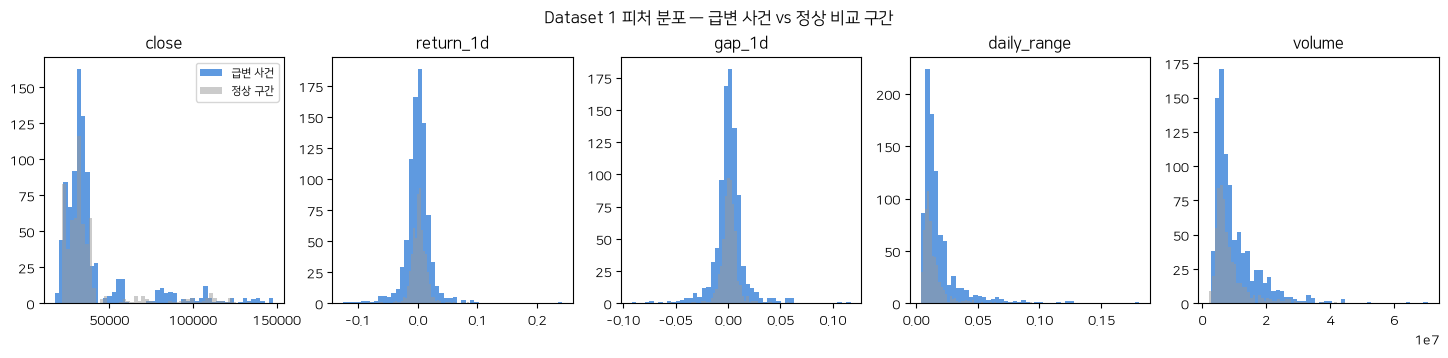

In [13]:
miss = rows[FEATURES].isna().sum()  # 피처별 결측 개수
skew = rows[FEATURES].skew()  # 피처별 왜도 (치우침 정도)
skew_log = np.log1p(rows["volume"]).skew()  # log1p 변환 후 거래량 왜도
print("결측:", miss.to_dict())  # 결측 출력
print("왜도:", skew.round(2).to_dict(), "| log1p(volume) 왜도:", round(float(skew_log), 2))  # 왜도 출력

fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))  # 피처 5개 히스토그램
for ax, c in zip(axes, FEATURES):  # 피처마다
    ax.hist(rows[c].dropna(), bins=50, color="#2a78d6", alpha=0.75, label="급변 사건")  # 사건 분포
    ax.hist(nrows[c].dropna(), bins=50, color="#999999", alpha=0.5, label="정상 구간")  # 정상 구간 분포
    ax.set_title(c)  # 피처 이름
axes[0].legend(fontsize=8)  # 범례
fig.suptitle("Dataset 1 피처 분포 — 급변 사건 vs 정상 비교 구간", y=1.03)  # 제목
fig.savefig(FIG / "01_feature_distributions.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

### 급변 구간 시각화
위: 종가와 표본 사건(파란 음영). 가운데: 20일·60일 변동성 교차. 아래: 사건 길이 분포 — 1–3일짜리 짧은 교차 사건 비중을 따로 표시한다.

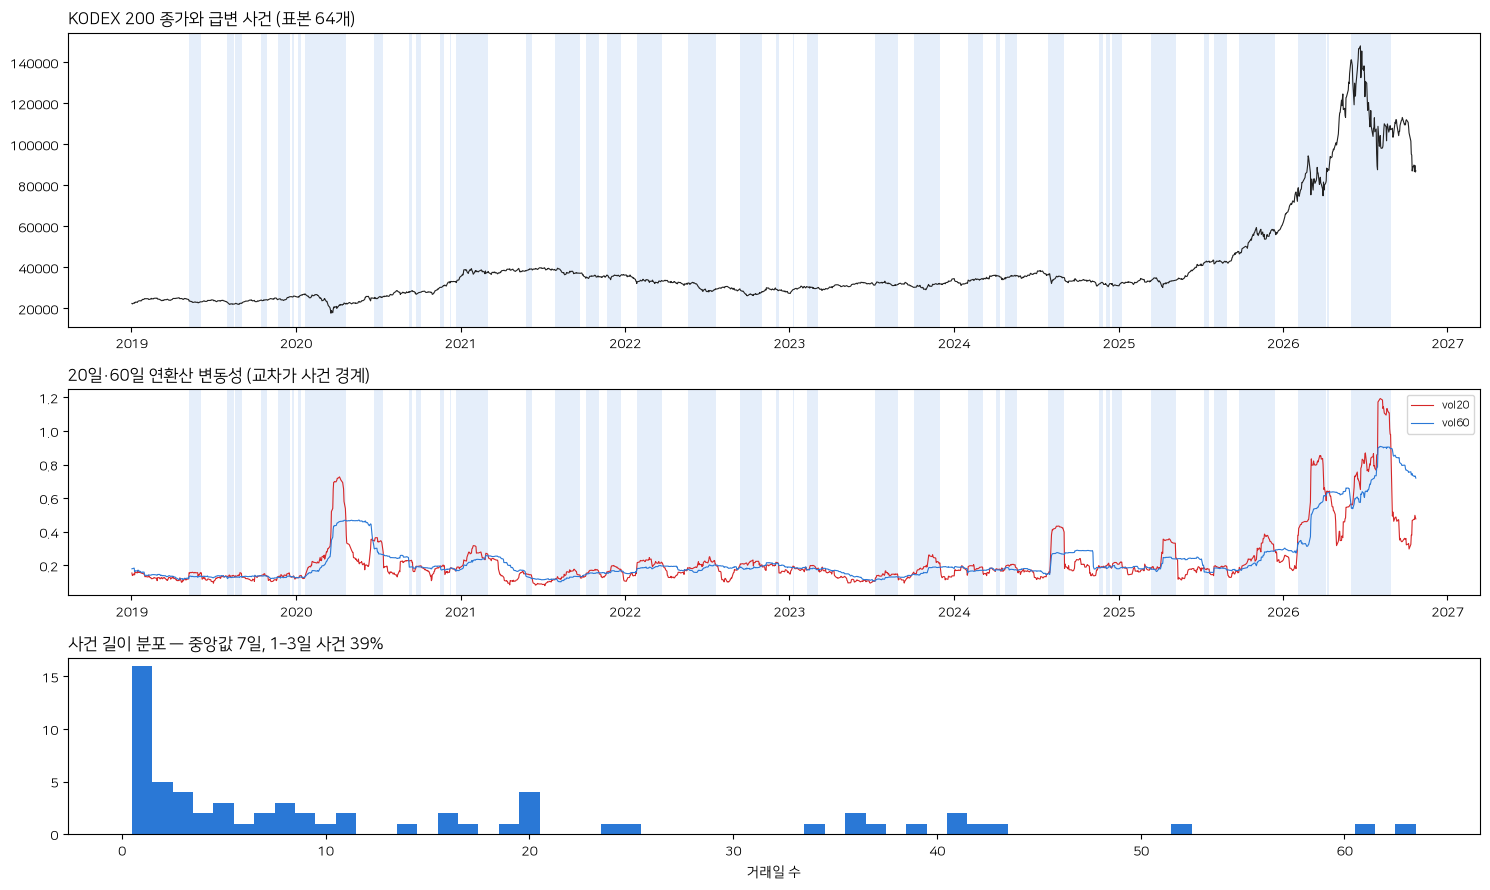

In [14]:
a = aud[aud["date"] >= pd.Timestamp(ANALYSIS_START)]  # 분석 기간 감사표
fig, ax = plt.subplots(3, 1, figsize=(15, 9), gridspec_kw={"height_ratios": [2, 1.4, 1.2]})  # 3단 그림
ax[0].plot(a["date"], a["close"], color="#222222", lw=0.8)  # 종가
ax[1].plot(a["date"], a["vol20"], color="#d62728", lw=0.8, label="vol20")  # 20일 변동성
ax[1].plot(a["date"], a["vol60"], color="#2a78d6", lw=0.8, label="vol60")  # 60일 변동성
for w in main_ev.itertuples():  # 표본 사건마다 음영
    for k in (0, 1):  # 위 두 그림에 같이
        ax[k].axvspan(w.start_date, w.end_date, color="#2a78d6", alpha=0.12, lw=0)  # 사건 구간
ax[0].set_title(f"KODEX 200 종가와 급변 사건 (표본 {len(main_ev)}개)", loc="left")  # 제목
ax[1].legend(loc="upper right", fontsize=8)  # 범례
ax[1].set_title("20일·60일 연환산 변동성 (교차가 사건 경계)", loc="left")  # 제목
dur = main_ev["duration_days"]  # 사건 길이
ax[2].hist(dur, bins=np.arange(1, dur.max() + 2) - 0.5, color="#2a78d6")  # 길이 히스토그램 (1일 단위)
short_share = float((dur <= 3).mean())  # 1–3일 사건 비율
ax[2].set_title(f"사건 길이 분포 — 중앙값 {dur.median():.0f}일, 1–3일 사건 {short_share:.0%}", loc="left")  # 제목
ax[2].set_xlabel("거래일 수")  # 축 이름
fig.tight_layout()  # 여백 정리
fig.savefig(FIG / "01_regime_events.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

## 10. 학습·검증 분할과 표준화 — **보류 (모델 설계와 함께 결정)**
분할은 학습 모델과 함께 정해야 하므로 지금 적용하지 않는다. 대신 제안된 분할안(2019–2023 학습 / 2024 검증 / 2025 시험 진단 / 2026 관찰)의
**배경과 필요를 데이터로 추론한 의견**을 `split_manifest.json` 에 남긴다. 표준화도 학습 분할이 정해진 뒤 학습 분할에서만 적합해야 하므로 `scaler.json` 에는 규칙만 둔다.

In [15]:
yr_counts = main_ev.groupby("analysis_year").agg(n_events=("event_id", "size"), median_len=("duration_days", "median"), total_days=("duration_days", "sum"))  # 연도별 사건 수·길이
main_ev["crosses_year_boundary"] = main_ev["start_date"].dt.year != main_ev["end_date"].dt.year  # 연도를 넘는 사건
proposal = {"train_2019_2023": (2019, 2023), "val_2024": (2024, 2024), "test_2025": (2025, 2025), "observe_2026": (2026, 2026)}  # 제안 구간
prop_counts = {k: int(main_ev["analysis_year"].between(a0, a1).sum()) for k, (a0, a1) in proposal.items()}  # 구간별 사건 수 (시작 연도 기준)
cross = main_ev.loc[main_ev["crosses_year_boundary"], ["event_id", "start_date", "end_date", "duration_days"]]  # 경계 걸침 사건
split_manifest = {
    "split_status": "DEFERRED_UNTIL_MODEL_DESIGN",  # 분할 미적용
    "assignment": None,  # 배정하지 않음
    "events_by_year": yr_counts.reset_index().to_dict("records"),  # 연도별 사건 수
    "proposal_event_counts_by_start_year": prop_counts,  # 제안안별 사건 수
    "events_crossing_year_boundary": cross.assign(start_date=cross.start_date.dt.date.astype(str), end_date=cross.end_date.dt.date.astype(str)).to_dict("records"),  # 걸침 사건 목록
    "opinion": [  # 데이터에서 추론한 배경과 의견
        f"배경: 표본 단위가 '하루'가 아니라 '사건'({len(main_ev)}개, 길이 {int(dur.min())}–{int(dur.max())}일)이다. 같은 사건의 날짜가 학습·평가에 나뉘면 사건 내부 자기상관 때문에 평가가 낙관적으로 된다 → 이벤트 단위 분할 요구는 이 구조에서 나온다.",
        f"배경: 시간 순서 분할(과거 학습→미래 평가)은 실시간 탐지 상황을 흉내 내기 위한 것이다. 연도별 사건 수가 {yr_counts['n_events'].min()}–{yr_counts['n_events'].max()}개로 고르지 않다.",
        f"제안안 사건 수(시작 연도 기준): {prop_counts}. 검증·시험이 각각 1년이라 사건 수가 적다 — 복원오차 비교의 분산이 크므로 지표는 사건 수와 함께 보고해야 한다.",
        f"연도 경계 걸침 사건 {len(cross)}개: 시작 연도로 전체 사건을 배정하거나(권장 — 정보 누출 없음, 사건 보존), 분할 경계(2023/2024, 2024/2025, 2025/2026)에 걸린 사건만 평가에서 제외하는 방식 중 하나를 미리 정해야 한다.",
        "2019–2025 는 이미 탐색 분석에 쓰인 기간이다. 이 분할의 검증·시험 결과를 독립적인 사전 미사용 검증이라고 부르면 안 된다. 2026-10-24 이후 자료가 진짜 맹검 후보다.",
        "짧은 교차 사건(1–3일)이 많으면 표본 수는 늘지만 정보량은 적다. 분할 전에 최소 길이를 둘지(현재 계약: 제한 없음) 모델 설계와 함께 사전 등록하는 것이 좋다.",
    ],
}
save_json(split_manifest, TRAIN / "split_manifest.json")  # 저장
scaler = {
    "status": "NOT_FITTED",  # 적합하지 않음
    "rule": "학습 분할의 실제 관측 위치(obs_mask & ~missing_mask)에서만 피처별 평균·표준편차(ddof=0)를 적합해 검증·시험·정상 구간에 같은 값을 적용한다. 평가 자료로 적합하지 않는다.",  # 규칙
    "transform_candidates": {"volume": {"transform": "log1p", "reason": f"왜도 {skew['volume']:.2f} → log1p 후 {skew_log:.2f}"}, "close": {"transform": "none (또는 사건 첫날 대비 비율)", "reason": "가격 수준은 연도에 따라 추세가 있어 전체 표준화 시 연도 정보가 섞인다 — Dataset 3 이 이 문제를 제거한 대안"}},  # 변환 후보와 근거
    "descriptive_only": rows[FEATURES].describe().round(6).to_dict(),  # 전체 표본 기술통계 (표준화에 쓰지 말 것)
}
save_json(scaler, TRAIN / "scaler.json")  # 저장
yr_counts  # 연도별 사건 수 표

,n_events,median_len,total_days
analysis_year,,,
2019,14,2.5,83
2020,10,6.5,151
2021,6,15.5,97
2022,5,34.0,120
2023,6,10.0,101
2024,13,7.0,110
2025,7,8.0,122
2026,3,41.0,107


## 11. 가변 길이 학습 데이터 출력
사건 길이가 다르므로 가장 긴 사건 길이 `max_len` 에 맞춰 0 으로 채운 3차원 배열을 만들고, **어디가 실제 날짜인지(`obs_mask`)와 어디가 결측인지(`missing_mask`)를 따로** 저장한다.

| 배열 | 모양 | 뜻 |
|---|---|---|
| `X` | (사건 수, max_len, 피처 수) float32 | 원값 (표준화 전). 패딩·결측 위치는 0 |
| `obs_mask` | (사건 수, max_len) bool | True = 실제 거래일 |
| `missing_mask` | (사건 수, max_len, 피처 수) bool | True = 계산 불가(결측) |
| `lengths` | (사건 수,) int32 | 사건별 원래 길이 |
| `event_ids` | (사건 수,) str | 사건 ID (모델 입력 아님) |

X: (64, 63, 5) | obs 실제 칸: 891 | 결측 칸: 0 | 정상 X: (57, 61, 5)


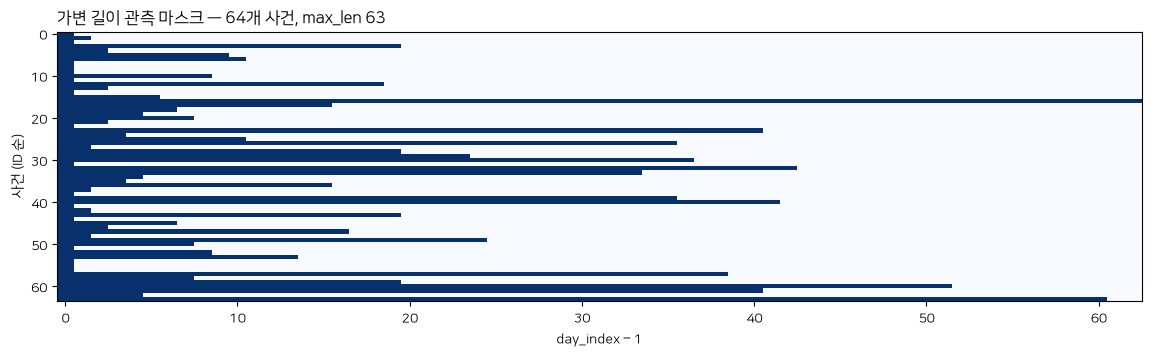

In [16]:
def to_tensor(tab: pd.DataFrame, id_col: str, feats: list):
    """하루 행 표 → (X, obs_mask, missing_mask, lengths, ids). ID 정렬 순서."""
    ids = np.array(sorted(tab[id_col].unique()))  # 결정적 순서
    groups = {k: g.sort_values("day_index") for k, g in tab.groupby(id_col)}  # 구간별 표 (날짜 순)
    lengths = np.array([len(groups[k]) for k in ids], dtype=np.int32)  # 길이
    T, F = int(lengths.max()), len(feats)  # 시간축 길이, 피처 수
    X = np.zeros((len(ids), T, F), dtype=np.float32)  # 값 배열 (0 패딩)
    obs = np.zeros((len(ids), T), dtype=bool)  # 실제 날짜 마스크
    mis = np.zeros((len(ids), T, F), dtype=bool)  # 결측 마스크
    for i, k in enumerate(ids):  # 구간마다
        v = groups[k][feats].to_numpy(dtype="float64")  # 값 (float64 로 먼저)
        L = len(v)  # 길이
        obs[i, :L] = True  # 실제 날짜 표시
        mis[i, :L] = ~np.isfinite(v)  # 결측(또는 비유한) 표시
        X[i, :L] = np.where(np.isfinite(v), v, 0.0).astype(np.float32)  # 결측은 0 (마스크로 구분)
    return X, obs, mis, lengths, ids  # 배열 묶음


X, obs, mis, lengths, ids = to_tensor(rows, "event_id", FEATURES)  # 사건 배열
np.savez_compressed(TRAIN / "features.npz", X=X, obs_mask=obs, missing_mask=mis, lengths=lengths, event_ids=ids, feature_names=np.array(FEATURES))  # 저장
Xn, obsn, misn, lenn, idsn = to_tensor(nrows, "ref_id", FEATURES)  # 정상 구간 배열
np.savez_compressed(TRAIN / "normal_reference_features.npz", X=Xn, obs_mask=obsn, missing_mask=misn, lengths=lenn, ref_ids=idsn, feature_names=np.array(FEATURES))  # 저장

tr_ev = main_ev[["event_id", "start_date", "end_date", "duration_days", "analysis_year", "crosses_year_boundary"]].sort_values("event_id").reset_index(drop=True)  # 학습용 이벤트 메타
valid_cnt = rows.assign(ok=rows[FEATURES].notna().all(axis=1)).groupby("event_id")["ok"].sum()  # 사건별 모든 피처 유효한 날 수
tr_ev["n_valid_rows"] = tr_ev["event_id"].map(valid_cnt).astype(int)  # 추가
tr_ev["fully_valid"] = tr_ev["n_valid_rows"] == tr_ev["duration_days"]  # 결측 없는 사건
save_pair(tr_ev, TRAIN / "events.parquet")  # 저장
feature_columns = [  # 피처 이름·순서·타입·식
    {"index": 0, "name": "close", "dtype": "float32", "unit": "원", "formula": "close_t", "uses": ["t"]},
    {"index": 1, "name": "return_1d", "dtype": "float32", "unit": "소수", "formula": "close_t/close_{t-1}-1", "uses": ["t", "close_{t-1}"]},
    {"index": 2, "name": "gap_1d", "dtype": "float32", "unit": "소수", "formula": "open_t/close_{t-1}-1", "uses": ["t", "close_{t-1}"]},
    {"index": 3, "name": "daily_range", "dtype": "float32", "unit": "소수", "formula": "(high_t-low_t)/close_t", "uses": ["t"]},
    {"index": 4, "name": "volume", "dtype": "float32", "unit": "주", "formula": "volume_t", "uses": ["t"]},
]
save_json({"features": feature_columns, "axis_order": "X[event, day, feature]", "non_input_columns": ["event_id", "date", "day_index", "start_date", "end_date"]}, TRAIN / "feature_columns.json")  # 저장
print("X:", X.shape, "| obs 실제 칸:", int(obs.sum()), "| 결측 칸:", int(mis.sum()), "| 정상 X:", Xn.shape)  # 배열 정보

fig, ax = plt.subplots(figsize=(14, 3.5))  # 관측 마스크 그림
ax.imshow(obs.astype(int), aspect="auto", cmap="Blues", interpolation="nearest")  # 사건×날짜 마스크
ax.set_xlabel("day_index − 1"); ax.set_ylabel("사건 (ID 순)")  # 축 이름
ax.set_title(f"가변 길이 관측 마스크 — {X.shape[0]}개 사건, max_len {X.shape[1]}", loc="left")  # 제목
fig.savefig(FIG / "01_obs_mask.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

## 12. 품질 검증 및 재현성 검사
계약 위반(미래정보·ID 불일치)은 `assert` 로 멈추고, 나머지는 PASS/FAIL 로 기록한다.

In [17]:
chk = {}  # 검사 결과 사전
chk["raw_vs_clean_rows"] = {"raw": len(raw), "clean": len(df), "pass": len(df) == len(raw) - identical_dup}  # 행 수 비교
chk["dates_sorted_unique"] = bool(df["date"].is_monotonic_increasing and df["date"].is_unique)  # 정렬·고유
chk["event_id_unique"] = bool(ev["event_id"].is_unique)  # 이벤트 ID 고유
# 시작·종료 규칙 재검사: 시작 전날 False, 사건 안 모두 True, 하향 교차일 False
a_idx = aud.set_index("date")  # 날짜 인덱스 감사표
prev_valid = aud.loc[aud["valid"], "date"].reset_index(drop=True)  # 판정 가능한 날 목록
rule_ok = True  # 규칙 통과 여부
for w in main_ev.itertuples():  # 표본 사건마다
    seg = a_idx.loc[w.start_date:w.end_date, "state"]  # 사건 안 상태
    p = prev_valid[prev_valid < w.start_date].iloc[-1]  # 시작 직전 판정일
    rule_ok &= bool(seg.all()) and (not a_idx.loc[p, "state"]) and (not a_idx.loc[w.cross_down_date, "state"])  # 세 조건
chk["event_start_end_rule"] = bool(rule_ok)  # 기록
chk["length_equals_rows"] = bool((rows.groupby("event_id").size().reindex(main_ev["event_id"]).to_numpy() == main_ev["duration_days"].to_numpy()).all())  # 길이=행 수
chk["feature_count"] = {"expected": 5, "actual": int(X.shape[2]), "pass": X.shape[2] == 5}  # 피처 수
chk["feature_dtype_float32"] = X.dtype == np.float32  # dtype
chk["no_inf"] = bool(np.isfinite(rows[FEATURES].to_numpy(dtype="float64")[~rows[FEATURES].isna().to_numpy()]).all())  # 무한대 없음
chk["missing_in_events"] = {"count": int(mis.sum()), "reason": "표본 사건은 2019 이후라 직전 종가가 항상 있음 — 결측 0 이어야 함", "pass": int(mis.sum()) == 0}  # 결측 사유
# 미래정보 검사: 원천(클리닝 표)에서 t, t-1 만으로 다시 계산해 일치 확인
src = df.set_index("date")  # 원천 날짜 인덱스
pos = df.reset_index().set_index("date")["index"]  # 날짜 → 행 위치
re = pd.DataFrame({  # 재계산 (행 위치 기반)
    "close": src.loc[rows["date"], "close"].to_numpy(),
    "return_1d": src.loc[rows["date"], "close"].to_numpy() / df["close"].to_numpy()[pos[rows["date"]].to_numpy() - 1] - 1,
    "gap_1d": src.loc[rows["date"], "open"].to_numpy() / df["close"].to_numpy()[pos[rows["date"]].to_numpy() - 1] - 1,
    "daily_range": ((src.loc[rows["date"], "high"] - src.loc[rows["date"], "low"]) / src.loc[rows["date"], "close"]).to_numpy(),
    "volume": src.loc[rows["date"], "volume"].to_numpy(),
})
max_diff = float(np.nanmax(np.abs(re.to_numpy() - rows[FEATURES].to_numpy(dtype="float64"))))  # 최대 차이
assert max_diff < 1e-9, "피처가 t·t−1 원천 재계산과 다르다"  # 계약 위반이면 중단
chk["no_future_info_recompute_max_diff"] = max_diff  # 기록
# 미래 오염 검사: 미래 행을 바꿔도 과거 피처가 그대로인지 (격리된 복사본에서만 시험)
probe = df.copy()  # 격리 복사본 (최종 데이터에 쓰지 않음)
cut = len(probe) // 2  # 중간 지점
probe.loc[cut:, ["open", "high", "low", "close", "volume"]] *= 1.5  # 중간 이후 값만 변경
pf = probe["close"] / probe["close"].shift(1) - 1  # 같은 식으로 재계산
chk["future_perturbation_no_effect"] = bool(np.allclose(pf.iloc[1:cut], feat["return_1d"].iloc[1:cut]))  # 이전 값 불변이어야 함
chk["normal_no_overlap_with_events"] = bool(not nrows["date"].isin(aud.loc[aud["event_id"].notna(), "date"]).any() and nrows["date"].is_unique)  # 정상 구간 비중복
chk["normal_state_all_false"] = bool((~a_idx.loc[nrows["date"], "state"]).all())  # 정상 구간은 모두 급변 아님
chk["scaler_not_fitted"] = scaler["status"] == "NOT_FITTED"  # 분할 보류 중 표준화 미적합
chk["split_overlap"] = "N/A — 분할 보류"  # 분할 중복 검사는 해당 없음
fails = [k for k, v in chk.items() if (v is False) or (isinstance(v, dict) and v.get("pass") is False)]  # 실패 항목
status = "TRAIN_READY" if not fails else "PARTIAL"  # 상태 판정 (분할은 별도 표기)
validation = {"dataset": "dataset_1", "checks": chk, "fails": fails, "status": status, "split_status": "DEFERRED_UNTIL_MODEL_DESIGN"}  # 검증 보고
save_json(validation, QUALITY / "dataset_1_validation.json")  # 저장

outputs_hash = {p: content_hash(pd.read_parquet(ROOT / p)) for p in ["data/clean/069500_daily_clean.parquet", "data/events/069500_regime_events.parquet", "data/events/normal_reference_windows.parquet", "data/processed/dataset_1/event_rows.parquet", "data/processed/dataset_1/normal_reference.parquet", "data/training/dataset_1/events.parquet"]}  # 출력 내용 해시
outputs_hash["features.npz:X"] = hashlib.sha256(X.tobytes()).hexdigest()  # 배열 해시
manifest = {"dataset": "dataset_1", "status": status, "split_status": "DEFERRED_UNTIL_MODEL_DESIGN", "raw_sha256": meta["sha256"], "raw_collected_at": meta["collected_at"], "versions": VERSIONS, "n_events": int(X.shape[0]), "n_normal_refs": int(Xn.shape[0]), "tensor_shape": list(X.shape), "features": FEATURES, "outputs_content_hash": outputs_hash, "validation_fails": fails}  # 데이터 버전·해시·상태
save_json(manifest, TRAIN / "dataset_manifest.json")  # 저장
print(json.dumps({"status": status, "fails": fails}, ensure_ascii=False))  # 결과
chk  # 전체 검사 표

{"status": "TRAIN_READY", "fails": []}


{'raw_vs_clean_rows': {'raw': 2403, 'clean': 2403, 'pass': True},
 'dates_sorted_unique': True,
 'event_id_unique': True,
 'event_start_end_rule': True,
 'length_equals_rows': True,
 'feature_count': {'expected': 5, 'actual': 5, 'pass': True},
 'feature_dtype_float32': True,
 'no_inf': True,
 'missing_in_events': {'count': 0,
  'reason': '표본 사건은 2019 이후라 직전 종가가 항상 있음 — 결측 0 이어야 함',
  'pass': True},
 'no_future_info_recompute_max_diff': 0.0,
 'future_perturbation_no_effect': True,
 'normal_no_overlap_with_events': True,
 'normal_state_all_false': True,
 'scaler_not_fitted': True,
 'split_overlap': 'N/A — 분할 보류'}

## 13. 결과 요약 및 데이터 계약
- **원천**: FDR 단일 출처 (pykrx 는 비교만 — 결과는 `data/raw/069500_pykrx_check.json`). 원천 스냅샷 `data/raw/069500_fdr_raw.parquet` (+csv, SHA-256 은 메타 JSON).
- **클리닝**: 값 수정 없음. 검사 결과 `data/quality/cleaning_report.json`.
- **급변 구간**: `data/events/069500_regime_events.parquet` — `in_main_sample` 이 True 인 사건만 학습 표본. 판정값은 `regime_daily_audit.parquet` (모델 입력 아님).
- **Dataset 1**: `data/processed/dataset_1/event_rows.parquet` (원값), `normal_reference.parquet` (정상 비교), `data/training/dataset_1/` (배열·마스크·메타).
- **분할·표준화**: 보류. `split_manifest.json` 의 의견과 `scaler.json` 의 규칙을 학습 단계에서 적용한다.
- 상태 판정은 `dataset_manifest.json` 의 `status` 와 `split_status` 를 함께 본다.